In [1]:
import io
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [ ]:
# 1. Upload do arquivo no Google Colab
from google.colab import files
uploaded = files.upload()
nome_arquivo = list(uploaded.keys())[0]
df = pd.read_csv(io.BytesIO(uploaded[nome_arquivo]))


In [3]:
# 2. Tratamento de dados (remoção de duplicatas)
duplicados = df.duplicated(subset=['text']).sum()
print(f"Linhas duplicadas encontradas: {duplicados}")
df = df.drop_duplicates(subset=['text']).reset_index(drop=True)
print(f"Total de registros após limpeza: {len(df)}")

Linhas duplicadas encontradas: 178
Total de registros após limpeza: 4993


In [4]:
# 2. Separa os dados em 80% treino e 20% teste
X = df['text']
y = df['label_num']  # 0: normal, 1: spam
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

In [5]:
# 3. Cria e treina o modelo Naive Bayes com TF-IDF
modelo = Pipeline([
    ('tfidf', TfidfVectorizer(stop_words='english', lowercase=True)),
    ('nb', MultinomialNB())
])
modelo.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('tfidf', ...), ('nb', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None
,"lowercase lowercase: bool, default=TrueConvert all characters to lowercase before tokenizing.",True
,"preprocessor preprocessor: callable, default=NoneOverride the preprocessing (string transformation) stage whilepreserving the tokenizing and n-grams generation steps.Only applies if ``analyzer`` is not callable.",None
,"tokenizer tokenizer: callable, default=NoneOverride the string tokenization step while preserving thepreprocessing and n-grams generation steps.Only applies if ``analyzer == 'word'``.",None



Acurácia: 93.39%

              precision    recall  f1-score   support

         Ham       0.92      0.99      0.96       706
        Spam       0.98      0.79      0.88       293

    accuracy                           0.93       999
   macro avg       0.95      0.89      0.92       999
weighted avg       0.94      0.93      0.93       999



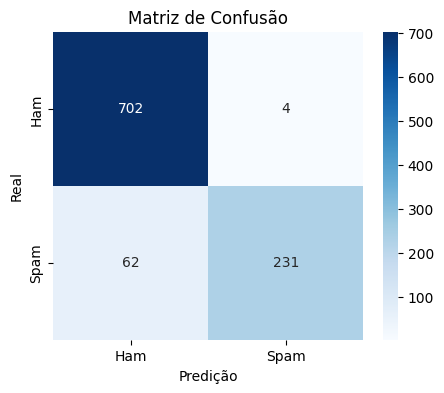

In [6]:
# 4. Avalia o desempenho no conjunto de teste
y_pred = modelo.predict(X_test)
print(f"\nAcurácia: {accuracy_score(y_test, y_pred) * 100:.2f}%\n")
print(classification_report(y_test, y_pred, target_names=['Ham', 'Spam']))
# Matriz de confusão
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'])
plt.xlabel('Predição')
plt.ylabel('Real')
plt.title('Matriz de Confusão')
plt.show()

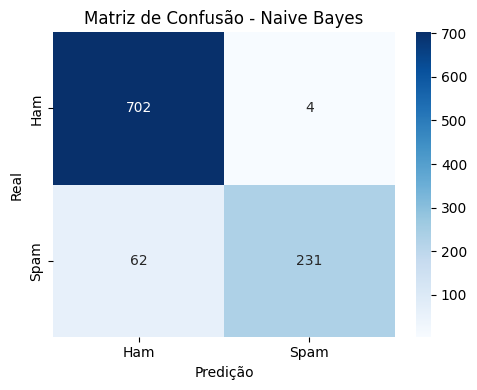

Resultados do Naive Bayes salvos com sucesso!


In [7]:

from pathlib import Path

# Cria a pasta de resultados do Naive Bayes
pasta_resultados = Path("resultados/naive_bayes")
pasta_resultados.mkdir(parents=True, exist_ok=True)

# Calcula as métricas detalhadas
relatorio = classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Ham", "Spam"],
    output_dict=True,
    zero_division=0
)

# Organiza os resultados em uma tabela
resultados = pd.DataFrame([{
    "Modelo": "Naive Bayes",
    "Acuracia": accuracy_score(y_test, y_pred),
    "Precisao_Ham": relatorio["Ham"]["precision"],
    "Recall_Ham": relatorio["Ham"]["recall"],
    "F1_Ham": relatorio["Ham"]["f1-score"],
    "Precisao_Spam": relatorio["Spam"]["precision"],
    "Recall_Spam": relatorio["Spam"]["recall"],
    "F1_Spam": relatorio["Spam"]["f1-score"],
    "Treinamento": len(X_train),
    "Teste": len(X_test)
}])

# Salva as métricas
resultados.to_csv(
    pasta_resultados / "metricas.csv",
    index=False
)

# Salva a matriz de confusão em CSV
matriz = confusion_matrix(y_test, y_pred, labels=[0, 1])

pd.DataFrame(
    matriz,
    index=["Real_Ham", "Real_Spam"],
    columns=["Previsto_Ham", "Previsto_Spam"]
).to_csv(pasta_resultados / "matriz_confusao.csv")

# Salva a imagem da matriz de confusão
plt.figure(figsize=(5, 4))
sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)
plt.xlabel("Predição")
plt.ylabel("Real")
plt.title("Matriz de Confusão - Naive Bayes")
plt.tight_layout()
plt.savefig(pasta_resultados / "matriz_confusao.png", dpi=300)
plt.show()

print("Resultados do Naive Bayes salvos com sucesso!")
